In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [5]:
# ==================================================
# STAGE 1: LOADING AND PREPROCESSING IMAGE DATA
# ==================================================

train_data = pd.read_csv('cifar-10.csv')

In [11]:
# Separate features and labels
X = train_data.drop('label', axis=1).values
y = train_data['label'].values

# Normalize pixel values
X = X.astype('float32') / 255.0

# Reshape images
# CIFAR-10 CSV stores RGB channel values consecutively
X = X.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

# Split dataset into training and testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
# ==================================================
# STAGE 2: DEFINING THE CNN MODEL ARCHITECTURE
# ==================================================

# CIFAR-10 has 10 classes
num_classes = 10

model = keras.Sequential([
    layers.Input(shape=x_train.shape[1:]),

    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),

    # Fully Connected Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(num_classes, activation='softmax')
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,048,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# ==================================================
# STAGE 3: TRAINING THE CNN MODEL
# ==================================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 130s 193ms/step - accuracy: 0.3720 - loss: 1.7218 - val_accuracy: 0.5077 - val_loss: 1.3615
Epoch 2/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 100s 178ms/step - accuracy: 0.5113 - loss: 1.3534 - val_accuracy: 0.5943 - val_loss: 1.1366
Epoch 3/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 138s 170ms/step - accuracy: 0.5769 - loss: 1.1896 - val_accuracy: 0.6248 - val_loss: 1.0607
Epoch 4/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 96s 171ms/step - accuracy: 0.6229 - loss: 1.0714 - val_accuracy: 0.6735 - val_loss: 0.9382
Epoch 5/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 101s 179ms/step - accuracy: 0.6621 - loss: 0.9697 - val_accuracy: 0.6842 - val_loss: 0.8990
Epoch 6/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 72s 128ms/step - accuracy: 0.6971 - loss: 0.8760 - val_accuracy: 0.7085 - val_loss: 0.8286
Epoch 7/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 63s 112ms/step - accuracy: 0.7194 - loss: 0.8038 - val_accuracy: 0.7203 - val_loss: 0.8140
Epoch 8/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 61s 108ms/step - accuracy: 0.7414 - los

In [14]:
# ==================================================
# STAGE 4: ESTIMATING MODEL PERFORMANCE
# ==================================================

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7267 - loss: 0.8137
Test Loss: 0.813746988773346
Test Accuracy: 72.67000079154968 %


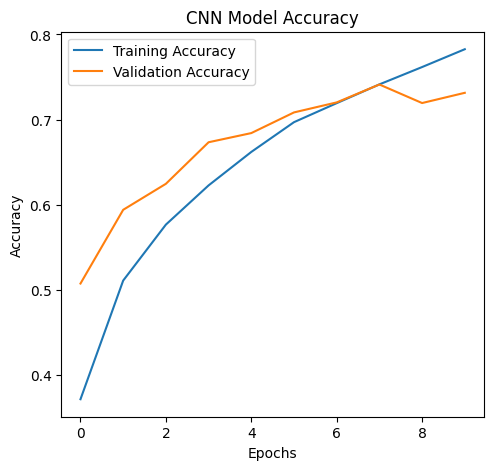

In [15]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

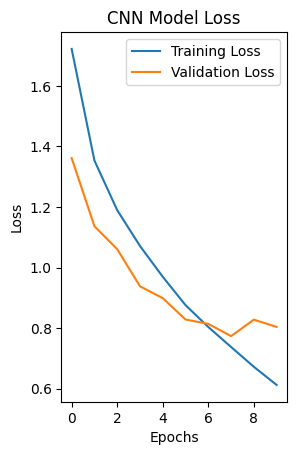

In [16]:
# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()